In [2]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080134
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}".encode()  
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp_env
[学号]       20244080134
[机器指纹] 805d3cbf1c55ffbb
[RUN_ID]   20244080134-805d3cbf1c55ffbb


# 实验1：NumPy 数组、数据类型与索引

In [11]:
int_arr = np.array([1, 2, 3, 4])
float_arr = np.array([1.0, 2.5, 3.75, 4.0])
bool_arr = np.array([True, False, True, False])

for name, arr in [("int", int_arr), ("float", float_arr), ("bool", bool_arr)]:
    print(f"{name:<5} | dtype={arr.dtype} | shape={arr.shape} | ndim={arr.ndim} | 内容={arr}")

print("\n--- 与 Python 列表的差别 ---")
py_list = [1, 2.5, True, "abc"]
print(f"Python 列表：{py_list}")
print(f"各元素类型：{[type(x).__name__ for x in py_list]} ")
print(f"NumPy 数组：{np.array([1, 2.5, True])} -> dtype={np.array([1, 2.5, True]).dtype}")

int   | dtype=int64 | shape=(4,) | ndim=1 | 内容=[1 2 3 4]
float | dtype=float64 | shape=(4,) | ndim=1 | 内容=[1.   2.5  3.75 4.  ]
bool  | dtype=bool | shape=(4,) | ndim=1 | 内容=[ True False  True False]

--- 与 Python 列表的差别 ---
Python 列表：[1, 2.5, True, 'abc']
各元素类型：['int', 'float', 'bool', 'str'] 
NumPy 数组：[1.  2.5 1. ] -> dtype=float64


In [4]:
base = np.arange(12)
print("原始一维数组：", base, "| shape =", base.shape)

arr_2d = base.reshape(3, 4)
arr_3d = base.reshape(2, 3, 2)

print("\n(3, 4)：")
print(arr_2d)
print("shape =", arr_2d.shape, "| ndim =", arr_2d.ndim)

print("\n(2, 3, 2)：")
print(arr_3d)
print("shape =", arr_3d.shape, "| ndim =", arr_3d.ndim)

print("\n元素总数：", base.size, "=", 3 * 4, "=", 2 * 3 * 2, "-> 三者相等才能 reshape")
print("错误示例（元素总数不匹配）：")
try:
    base.reshape(5, 3)
except ValueError as e:
    print("  ValueError:", e)

原始一维数组： [ 0  1  2  3  4  5  6  7  8  9 10 11] | shape = (12,)

(3, 4)：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape = (3, 4) | ndim = 2

(2, 3, 2)：
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
shape = (2, 3, 2) | ndim = 3

元素总数： 12 = 12 = 12 -> 三者相等才能 reshape
错误示例（元素总数不匹配）：
  ValueError: cannot reshape array of size 12 into shape (5,3)


In [5]:
print("矩阵：")
print(arr_2d)

row2 = arr_2d[1, :]
print("\n第 2 行 arr_2d[1, :] ->", row2, "| shape =", row2.shape)

col_1_to_3 = arr_2d[:, 1:4]
print("\n第 1 至第 3 列 arr_2d[:, 1:4] ->")
print(col_1_to_3)
print("shape =", col_1_to_3.shape)

gt6 = arr_2d[arr_2d > 6]
print("\n大于 6 的元素 arr_2d[arr_2d > 6] ->", gt6, "| shape =", gt6.shape)
print("说明：布尔索引返回的是一维数组，长度等于 True 的个数")

矩阵：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行 arr_2d[1, :] -> [4 5 6 7] | shape = (4,)

第 1 至第 3 列 arr_2d[:, 1:4] ->
[[ 1  2  3]
 [ 5  6  7]
 [ 9 10 11]]
shape = (3, 3)

大于 6 的元素 arr_2d[arr_2d > 6] -> [ 7  8  9 10 11] | shape = (5,)
说明：布尔索引返回的是一维数组，长度等于 True 的个数


In [6]:
a = np.arange(10)
print("原始数组：", a)

mask_or = (a < 2) | (a > 7)
print("\n方式一：(a < 2) | (a > 7)")
print("布尔掩码：", mask_or)
print("结果：", a[mask_or])

mask_or2 = np.logical_or(a < 2, a > 7)
print("\n方式二：np.logical_or(a < 2, a > 7) ->", a[mask_or2])

mask_and = (a > 3) & (a < 7)
print("\n方式三：(a > 3) & (a < 7)")
print("布尔掩码：", mask_and)
print("结果：", a[mask_and])

mask_and2 = np.logical_and(a > 3, a < 7)
print("\n方式四：np.logical_and(a > 3, a < 7) ->", a[mask_and2])

原始数组： [0 1 2 3 4 5 6 7 8 9]

方式一：(a < 2) | (a > 7)
布尔掩码： [ True  True False False False False False False  True  True]
结果： [0 1 8 9]

方式二：np.logical_or(a < 2, a > 7) -> [0 1 8 9]

方式三：(a > 3) & (a < 7)
布尔掩码： [False False False False  True  True  True False False False]
结果： [4 5 6]

方式四：np.logical_and(a > 3, a < 7) -> [4 5 6]


In [7]:
A = np.array([[1, 2],
              [3, 4]])
B = np.array([[5, 6],
              [7, 8]])

print("A =")
print(A)
print("\nB =")
print(B)

print("\n--- 逐元素乘法（对应位置相乘）---")
print("* 运算：")
print(A * B)
print("\nnp.multiply(A, B)：")
print(np.multiply(A, B))
print("\n两者是否完全相同：", np.array_equal(A * B, np.multiply(A, B)))

print("\n--- 矩阵乘法（行乘列求和）---")
print("@ 运算：")
print(A @ B)
print("\nnp.matmul(A, B)：")
print(np.matmul(A, B))
print("\n两者是否完全相同：", np.array_equal(A @ B, np.matmul(A, B)))
print("\n形状均为：", (A @ B).shape)

A =
[[1 2]
 [3 4]]

B =
[[5 6]
 [7 8]]

--- 逐元素乘法（对应位置相乘）---
* 运算：
[[ 5 12]
 [21 32]]

np.multiply(A, B)：
[[ 5 12]
 [21 32]]

两者是否完全相同： True

--- 矩阵乘法（行乘列求和）---
@ 运算：
[[19 22]
 [43 50]]

np.matmul(A, B)：
[[19 22]
 [43 50]]

两者是否完全相同： True

形状均为： (2, 2)


# 实验2：随机抽样、统计与缺失值
### 生成模拟成绩并 clip

In [ ]:
rng = np.random.default_rng(42)
# 生成模拟成绩并 clip 到 [0, 100]，均值为 66，标准差为 8，样本数为 1000，随机种子为 42
scores = rng.normal(loc=66, scale=8, size=1000)
# 打印 clip 前的统计信息
print("clip 前：min =", scores.min(), "| max =", scores.max())

scores = np.clip(scores, 0, 100)

print("\n样本数  :", scores.size)
print("最小值  :", scores.min())
print("最大值  :", scores.max())
print("均值    :", scores.mean())
print("标准差  :", scores.std())
print("极差    :", scores.max() - scores.min())
print("clip 后是否全部落在 [0, 100]：", np.all((scores >= 0) & (scores <= 100)))

clip 前：min = 36.81269739828173 | max = 91.43082943494028

样本数  : 1000
最小值  : 36.81269739828173
最大值  : 91.43082943494028
均值    : 65.76886759203244
标准差  : 7.909778843172064
极差    : 54.61813203665855
clip 后是否全部落在 [0, 100]： True


### 不放回抽样（均匀 vs 加权）

In [19]:
pool = np.arange(1, 100,10)
print("候选池：", pool)

uniform_sample = rng.choice(pool, size=5, replace=False)
# 均匀抽样（每个整数等概率）
print("\n均匀抽样（每个整数等概率）：", uniform_sample)

weights = pool / pool.sum()
# 计算每个整数的权重（与整数大小成正比）
print("\n权重（与整数大小成正比）：", np.round(weights, 4), "| 权重和 =", weights.sum())

weighted_sample = rng.choice(pool, size=5, replace=False, p=weights)
print("加权抽样（大整数更易被抽中）：", weighted_sample)

候选池： [ 1 11 21 31 41 51 61 71 81 91]

均匀抽样（每个整数等概率）： [51 61 31 41 71]

权重（与整数大小成正比）： [0.0022 0.0239 0.0457 0.0674 0.0891 0.1109 0.1326 0.1543 0.1761 0.1978] | 权重和 = 1.0
加权抽样（大整数更易被抽中）： [71 51 91 61 81]


### 随机排列 vs 原地打乱

In [20]:
original = np.arange(1, 11)

print("--- 方式一：np.random.permutation（返回新数组，原数组不变）---")
print("操作前原数组：", original)
permuted = rng.permutation(original)
print("返回的新数组：", permuted)
print("操作后原数组：", original)
print("原数组是否被改变：", not np.array_equal(original, np.arange(1, 11)))

print("\n--- 方式二：np.random.shuffle（原地打乱，无返回值）---")
to_shuffle = np.arange(1, 11)
print("操作前数组：", to_shuffle)
result = rng.shuffle(to_shuffle)
print("shuffle 的返回值：", result)
print("操作后数组：", to_shuffle)
print("原数组是否被改变：", not np.array_equal(to_shuffle, np.arange(1, 11)))

--- 方式一：np.random.permutation（返回新数组，原数组不变）---
操作前原数组： [ 1  2  3  4  5  6  7  8  9 10]
返回的新数组： [ 1  8  7  2  3 10  5  9  4  6]
操作后原数组： [ 1  2  3  4  5  6  7  8  9 10]
原数组是否被改变： False

--- 方式二：np.random.shuffle（原地打乱，无返回值）---
操作前数组： [ 1  2  3  4  5  6  7  8  9 10]
shuffle 的返回值： None
操作后数组： [ 4 10  5  7  8  1  3  9  2  6]
原数组是否被改变： True


#### 缺失值与统计函数

In [ ]:
scores_nan = scores.copy()
# 10、20、40 个位置的值设为 nan，模拟缺失值
scores_nan[[10, 20, 40]] = np.nan

print("第 10、20、40 个位置的值：", scores_nan[[10, 20, 40]])

print("\n--- 普通统计 ---")
print("普通均值 np.mean          :", np.mean(scores_nan))
print("普通求和 np.sum           :", np.sum(scores_nan))
print("普通标准差 np.std         :", np.std(scores_nan))

print("\n--- 忽略缺失值 ---")
print("nanmean（忽略 nan 的均值）:", np.nanmean(scores_nan))
print("nansum                    :", np.nansum(scores_nan))
print("nanstd                    :", np.nanstd(scores_nan))

nan_count = np.isnan(scores_nan).sum()
print("\n缺失值个数 np.isnan().sum():", nan_count)
print("缺失值占比：{:.2%}".format(nan_count / scores_nan.size))

第 10、21、41 个位置的值： [nan nan nan]

--- 普通统计 ---
普通均值 np.mean          : nan
普通求和 np.sum           : nan
普通标准差 np.std         : nan

--- 忽略缺失值 ---
nanmean（忽略 nan 的均值）: 65.76222127426512
nansum                    : 65564.93461044232
nanstd                    : 7.915273821983374

缺失值个数 np.isnan().sum(): 3
缺失值占比：0.30%


#### 结论：nan 具有'传染性'，任何含 nan 的普通统计函数结果都会变成 nan；必须用 np.nanmean / np.nansum / np.nanstd 等 nan 感知函数才能跳过缺失值。

### 整理成内存表格变量

In [25]:
index_array = np.arange(1, scores_nan.size + 1)

score_df = pd.DataFrame({
    "序号": index_array,
    "成绩": scores_nan,
})

print("表格形状：", score_df.shape)
print("列名：", list(score_df.columns))
print("缺失值个数：", int(score_df["成绩"].isna().sum()))
print("\n前 12 行：")
print(score_df.head(12))
print("\n第 9~12 行（含 nan）：")
print(score_df.iloc[9:12])
print("\n表格仅存在于内存变量 score_df 中，未写入磁盘。")

表格形状： (1000, 2)
列名： ['序号', '成绩']
缺失值个数： 3

前 12 行：
    序号         成绩
0    1  68.437737
1    2  57.680127
2    3  72.003610
3    4  73.524518
4    5  50.391718
5    6  55.582564
6    7  67.022723
7    8  63.470059
8    9  65.865591
9   10  59.175649
10  11        NaN
11  12  72.222335

第 9~12 行（含 nan）：
    序号         成绩
9   10  59.175649
10  11        NaN
11  12  72.222335

表格仅存在于内存变量 score_df 中，未写入磁盘。


# 实验3：SciPy 数值计算与 Matplotlib 可视化
### 解线性方程

In [26]:
from scipy import linalg

A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([9.0, 8.0])

x = linalg.solve(A, b)
print("解向量 x =", x)
print("即 x =", x[0], ", y =", x[1])

print("\n--- 用 NumPy 代入验证 ---")
print("A @ x        =", A @ x)
print("原右端项 b   =", b)
print("是否相等     =", np.allclose(A @ x, b))

print("\n--- 与解析解对比 ---")
print("方程组：3x + y = 9, x + 2y = 8")
print("解析解：x = (9*2 - 8*1)/(3*2 - 1*1) = 2, y = (3*8 - 1*9)/5 = 3")

解向量 x = [2. 3.]
即 x = 2.0 , y = 3.0

--- 用 NumPy 代入验证 ---
A @ x        = [9. 8.]
原右端项 b   = [9. 8.]
是否相等     = True

--- 与解析解对比 ---
方程组：3x + y = 9, x + 2y = 8
解析解：x = (9*2 - 8*1)/(3*2 - 1*1) = 2, y = (3*8 - 1*9)/5 = 3


### 求根

In [27]:
from scipy import optimize

def f(x):
    return x**2 - 2

root_pos = optimize.root(f, x0=1.0)
print("初始猜测 x0=1.0（寻找正根）")
print("  是否成功 success =", root_pos.success)
print("  求得的根 x      =", root_pos.x)
print("  函数值 f(x)     =", f(root_pos.x), "| 是否接近 0:", np.isclose(f(root_pos.x), 0))

root_neg = optimize.root(f, x0=-1.0)
print("\n初始猜测 x0=-1.0（寻找负根）")
print("  是否成功 success =", root_neg.success)
print("  求得的根 x      =", root_neg.x)
print("  函数值 f(x)     =", f(root_neg.x), "| 是否接近 0:", np.isclose(f(root_neg.x), 0))

print("\n理论值：sqrt(2) =", np.sqrt(2), "| -sqrt(2) =", -np.sqrt(2))

初始猜测 x0=1.0（寻找正根）
  是否成功 success = True
  求得的根 x      = [1.41421356]
  函数值 f(x)     = [-8.8817842e-16] | 是否接近 0: [ True]

初始猜测 x0=-1.0（寻找负根）
  是否成功 success = True
  求得的根 x      = [-1.41421356]
  函数值 f(x)     = [-8.8817842e-16] | 是否接近 0: [ True]

理论值：sqrt(2) = 1.4142135623730951 | -sqrt(2) = -1.4142135623730951


### 求最小值并对比解析解

In [28]:
from scipy import optimize

def g(x):
    return x**2 + x + 2

result = optimize.minimize(g, x0=0.0)
print("是否成功 success :", result.success)
print("极小点 x*        :", result.x)
print("最小值 f(x*)     :", result.fun)

print("\n--- 与解析结果对比 ---")
print("f(x) = x^2 + x + 2 = (x + 1/2)^2 + 7/4")
print("解析极小点 x* = -0.5，最小值 7/4 = 1.75")
print("x* 是否一致      :", np.isclose(result.x[0], -0.5))
print("最小值是否一致   :", np.isclose(result.fun, 1.75))

是否成功 success : True
极小点 x*        : [-0.50000001]
最小值 f(x*)     : 1.75

--- 与解析结果对比 ---
f(x) = x^2 + x + 2 = (x + 1/2)^2 + 7/4
解析极小点 x* = -0.5，最小值 7/4 = 1.75
x* 是否一致      : True
最小值是否一致   : True


### 独立样本t检验

In [29]:
from scipy import stats

rng = np.random.default_rng(2024)

sample1 = rng.normal(loc=0.0, scale=1.0, size=100)
sample2 = rng.normal(loc=1.0, scale=1.0, size=100)

print("样本 1：均值 = {:.4f}, 标准差 = {:.4f}".format(sample1.mean(), sample1.std(ddof=1)))
print("样本 2：均值 = {:.4f}, 标准差 = {:.4f}".format(sample2.mean(), sample2.std(ddof=1)))

t_stat, p_value = stats.ttest_ind(sample1, sample2)
print("\nt 统计量 = {:.4f}".format(t_stat))
print("p 值     = {:.4e}".format(p_value))

alpha = 0.05
if p_value < alpha:
    print(f"\n判断：p = {p_value:.4e} < {alpha}，拒绝原假设，两组样本均值存在显著差异。")
else:
    print(f"\n判断：p = {p_value:.4e} >= {alpha}，不能拒绝原假设，无显著差异。")

样本 1：均值 = 0.0790, 标准差 = 0.8824
样本 2：均值 = 0.8563, 标准差 = 1.0823

t 统计量 = -5.5665
p 值     = 8.3781e-08

判断：p = 8.3781e-08 < 0.05，拒绝原假设，两组样本均值存在显著差异。


### Matplotlib 可视化（三张图）

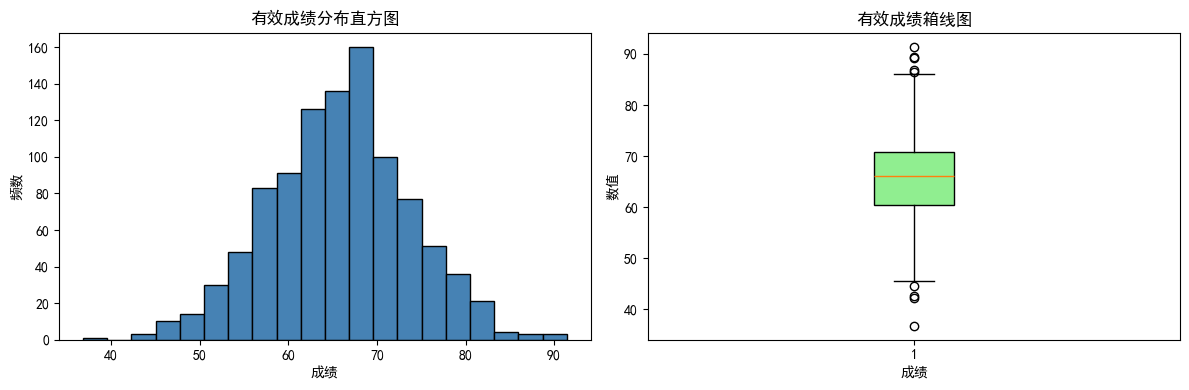

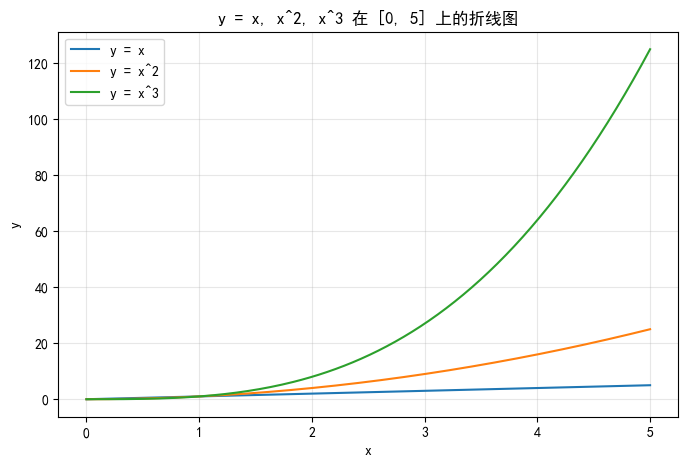

In [30]:
import matplotlib.pyplot as plt

matplotlib.rcParams["font.sans-serif"] = ["SimHei"]
matplotlib.rcParams["axes.unicode_minus"] = False

valid_scores = scores_nan[~np.isnan(scores_nan)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(valid_scores, bins=20, color="steelblue", edgecolor="black")
axes[0].set_title("有效成绩分布直方图")
axes[0].set_xlabel("成绩")
axes[0].set_ylabel("频数")

axes[1].boxplot(valid_scores, vert=True, patch_artist=True,
                boxprops=dict(facecolor="lightgreen"))
axes[1].set_title("有效成绩箱线图")
axes[1].set_xlabel("成绩")
axes[1].set_ylabel("数值")
plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(8, 5))
xs = np.linspace(0, 5, 200)
ax2.plot(xs, xs, label="y = x")
ax2.plot(xs, xs**2, label="y = x^2")
ax2.plot(xs, xs**3, label="y = x^3")
ax2.set_title("y = x, x^2, x^3 在 [0, 5] 上的折线图")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.show()

# 实验4：pandas Series、DataFrame 与内存中的CSV 读写

In [31]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引：", list(df.index))
print("列名：", list(df.columns))
print("\n前 3 行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [32]:
print("--- loc（按标签索引）---")
print(df.loc["Carol"])

print("\n--- iloc（按整数位置索引，Carol 是第 3 行 -> 位置 2）---")
print(df.iloc[2])

print("\n--- 筛选 Average >= 80 的学生 ---")
print(df[df["Average"] >= 80])

print("\n--- 用 loc 配合布尔条件，只看姓名 ---")
print(df.loc[df["Average"] >= 80, ["Group", "Average"]])

--- loc（按标签索引）---
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

--- iloc（按整数位置索引，Carol 是第 3 行 -> 位置 2）---
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

--- 筛选 Average >= 80 的学生 ---
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000

--- 用 loc 配合布尔条件，只看姓名 ---
      Group    Average
Name                  
Alice     A  91.000000
Carol     B  88.333333
Eva       A  85.666667
Frank     B  81.000000


In [ ]:
subjects = ["Math", "English", "Python"]

col_mean = df[subjects].mean(axis=0)
print("mean(axis=0) —— 三科列均值：")
print(col_mean)

row_mean = df[subjects].mean(axis=1)
print("\nmean(axis=1) —— 每名学生行均值：")
print(row_mean)

# 说明：axis=0 沿行方向压缩（得到每列一个值），axis=1 沿列方向压缩（得到每行一个值）

mean(axis=0) —— 三科列均值：
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

mean(axis=1) —— 每名学生行均值：
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64

说明：axis=0 沿行方向压缩（得到每列一个值），axis=1 沿列方向压缩（得到每行一个值）


In [34]:
subjects = ["Math", "English", "Python"]

df["MaxScore"] = df[subjects].apply(lambda row: row.max(), axis=1)
print("apply() —— 每人三科最高分：")
print(df["MaxScore"])

print("\nagg() —— 每科最小值、均值、最大值：")
print(df[subjects].agg(["min", "mean", "max"]))

print("\nrank() —— 按 Math 降序排名（数值越大名次越前）：")
df["MathRank"] = df["Math"].rank(ascending=False, method="min")
print(df[["Math", "MathRank"]].sort_values("Math", ascending=False))

apply() —— 每人三科最高分：
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: MaxScore, dtype: int64

agg() —— 每科最小值、均值、最大值：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

rank() —— 按 Math 降序排名（数值越大名次越前）：
       Math  MathRank
Name                 
Carol    91       1.0
Alice    88       2.0
Frank    84       3.0
Eva      79       4.0
Bob      72       5.0
David    65       6.0


In [36]:
subjects = ["Math", "English", "Python"]

group_summary = df.groupby("Group").agg(
    人数=("Math", "count"),
    Math均分=("Math", "mean"),
    English均分=("English", "mean"),
    Python均分=("Python", "mean"),
)
print("按 Group 分组：人数与三科平均分")
print(group_summary)

df["GroupPythonMean"] = df.groupby("Group")["Python"].transform("mean")
print("\ntransform('mean') —— 每行增加其所在组的 Python 平均分：")
print(df[["Group", "Python", "GroupPythonMean"]])

按 Group 分组：人数与三科平均分
       人数     Math均分  English均分   Python均分
Group                                     
A       3  79.666667  83.333333  87.000000
B       3  80.000000  78.333333  80.333333

transform('mean') —— 每行增加其所在组的 Python 平均分：
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [37]:
kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)

print("保留的组：", sorted(kept["Group"].unique()))
print("\n保留的组和学生：")
print(kept[["Group", "Python"]])

print("\n各组 Python 均分（供对照）：")
print(df.groupby("Group")["Python"].mean())

保留的组： ['A', 'B']

保留的组和学生：
      Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82

各组 Python 均分（供对照）：
Group
A    87.000000
B    80.333333
Name: Python, dtype: float64


In [38]:
subjects = ["Math", "English", "Python"]

cov_mx = df[subjects].cov()
print("协方差矩阵：")
print(cov_mx.round(3))

corr_mx = df[subjects].corr()
print("\n皮尔逊相关系数矩阵：")
print(corr_mx.round(3))

print("\n--- 选一对科目解释：Math 与 English ---")
print(f"cov(Math, English)  = {cov_mx.loc['Math', 'English']:.3f}")
print(f"corr(Math, English) = {corr_mx.loc['Math', 'English']:.3f}")

协方差矩阵：
           Math  English  Python
Math     98.167   62.567  74.933
English  62.567   93.367  62.533
Python   74.933   62.533  73.067

皮尔逊相关系数矩阵：
          Math  English  Python
Math     1.000    0.654   0.885
English  0.654    1.000   0.757
Python   0.885    0.757   1.000

--- 选一对科目解释：Math 与 English ---
cov(Math, English)  = 62.567
corr(Math, English) = 0.654
